Analysis of GDP, Personal Consumption Expenditure (PCE), and Unemployment Index

In [1]:
# Starter code: run this cell first and do not edit it.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Raw data import.
GDP = pd.read_csv('GDPC1.csv',  parse_dates=['observation_date'], index_col='observation_date')
PCE = pd.read_csv('PCEPI.csv',  parse_dates=['observation_date'], index_col='observation_date')
UNI = pd.read_csv('UNRATE.csv', parse_dates=['observation_date'], index_col='observation_date')

In [2]:
GDP.head()

,GDPC1
observation_date,
1947-01-01,2182.681
1947-04-01,2176.892
1947-07-01,2172.432
1947-10-01,2206.452
1948-01-01,2239.682


In [3]:
PCE.head()

,PCEPI
observation_date,
1959-01-01,15.164
1959-02-01,15.179
1959-03-01,15.189
1959-04-01,15.219
1959-05-01,15.227


In [4]:
UNI.head()

,UNRATE
observation_date,
1948-01-01,3.4
1948-02-01,3.8
1948-03-01,4.0
1948-04-01,3.9
1948-05-01,3.5


In [5]:
#combine as 1 file with year as index

df = pd.concat(
    [UNI.resample('YE').mean(),
     PCE.resample('YE').mean(),
     GDP.resample('YE').mean()],
    axis=1,
    sort=True,
)

df.index = df.index.year
df.index.name = 'year'
df = df.dropna()

print(df.head())

        UNRATE      PCEPI       GDPC1
year                                 
1959  5.450000  15.290500  3412.42125
1960  5.541667  15.541333  3500.27250
1961  6.691667  15.702333  3590.06625
1962  5.566667  15.886417  3810.12325
1963  5.641667  16.076500  3976.14175


In [10]:
#calculating growth 

df['gdp_growth'] = df['GDPC1'].pct_change() * 100
df['inflation']  = df['PCEPI'].pct_change() * 100

round(df.head(), 2)

,UNRATE,PCEPI,GDPC1,gdp_growth,inflation
year,,,,,
1959,5.45,15.29,3412.42,NaN,NaN
1960,5.54,15.54,3500.27,2.57,1.64
1961,6.69,15.70,3590.07,2.57,1.04
1962,5.57,15.89,3810.12,6.13,1.17
1963,5.64,16.08,3976.14,4.36,1.20


Regression Plot 

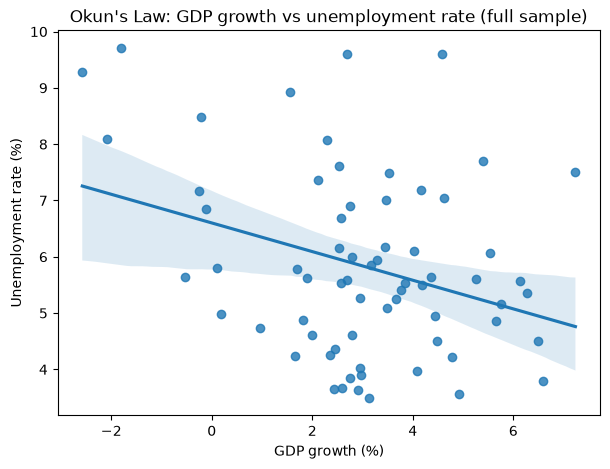

In [11]:
# 1) Full dataset of GDP vs Unemployment Rate
plt.figure(figsize=(7, 5))
sns.regplot(data=df, x='gdp_growth', y='UNRATE')
plt.title("Okun's Law: GDP growth vs unemployment rate (full sample)")
plt.xlabel('GDP growth (%)')
plt.ylabel('Unemployment rate (%)')
plt.show()

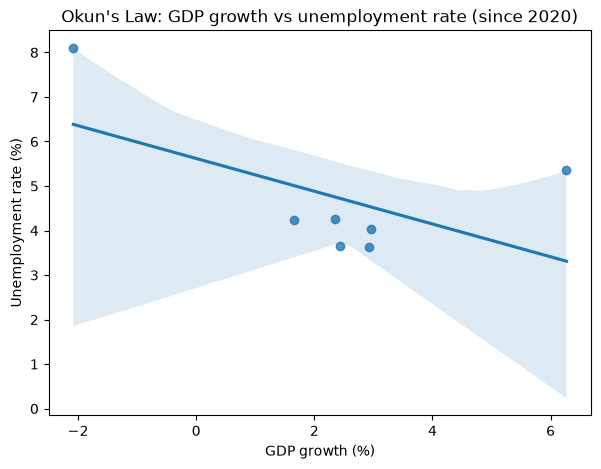

In [12]:
# 2) GDP vs Unemployment Rate, Since Covid
df_covid = df.loc[2020:]

plt.figure(figsize=(7, 5))
sns.regplot(data=df_covid, x='gdp_growth', y='UNRATE')
plt.title("Okun's Law: GDP growth vs unemployment rate (since 2020)")
plt.xlabel('GDP growth (%)')
plt.ylabel('Unemployment rate (%)')
plt.show()

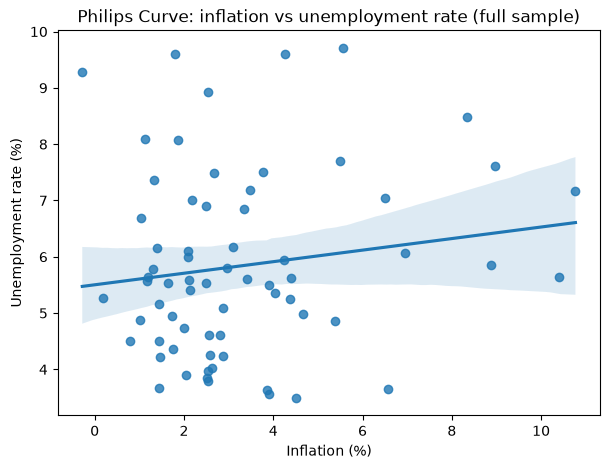

In [13]:
# 3) Inflation vs Unemployment (Philips Curve)

plt.figure(figsize=(7, 5))
sns.regplot(data=df, x='inflation', y='UNRATE')
plt.title("Philips Curve: inflation vs unemployment rate (full sample)")
plt.xlabel('Inflation (%)')
plt.ylabel('Unemployment rate (%)')
plt.show()

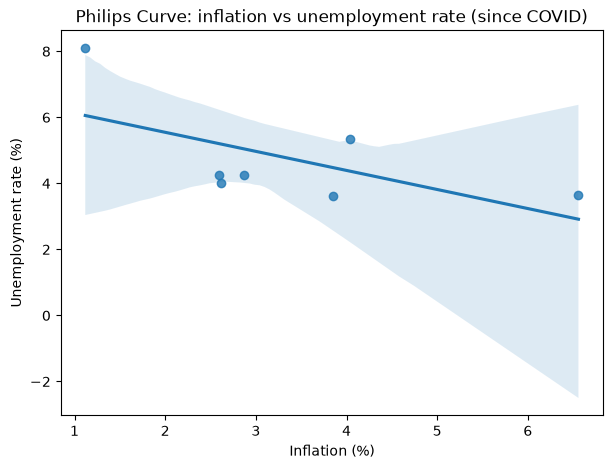

In [16]:
# 4) Inflation vs Unemployment (Philips Curve) - Since Covid

df_covid = df.loc[2020:]

plt.figure(figsize=(7, 5))
sns.regplot(data=df_covid, x='inflation', y='UNRATE')
plt.title("Philips Curve: inflation vs unemployment rate (since COVID)")
plt.xlabel('Inflation (%)')
plt.ylabel('Unemployment rate (%)')
plt.show()